# Bagian B — Logistic Regression

## B1. Deskripsi Dataset

Dataset yang dipakai adalah **Breast Cancer Wisconsin (Diagnostic)** dari Kaggle.

Data ini berisi hasil pengukuran sel dari pemeriksaan payudara. Satu baris mewakili satu sampel pemeriksaan. Tujuan kita adalah membuat model yang memprediksi apakah sampel masuk kelas **M** atau **B**.

- M berarti **Malignant**, yaitu ganas.
- B berarti **Benign**, yaitu jinak.

Dataset memiliki sekitar **569 baris** dan **33 kolom** sebelum beberapa kolom yang tidak diperlukan dibuang. Sebagian besar kolom adalah angka hasil pengukuran sel.

Beberapa fitur utama yang ada di dataset:

- `radius_mean`: rata-rata ukuran jari-jari sel.
- `texture_mean`: rata-rata tekstur atau pola permukaan sel.
- `perimeter_mean`: rata-rata keliling sel.
- `area_mean`: rata-rata luas sel.
- `smoothness_mean`: rata-rata tingkat kehalusan sel.
- `compactness_mean`: rata-rata bentuk padat sel.
- `concavity_mean`: rata-rata cekungan pada sel.
- `concave points_mean`: rata-rata titik cekung pada sel.
- `symmetry_mean`: rata-rata kesimetrisan sel.
- `fractal_dimension_mean`: ukuran kerumitan bentuk sel.

Selain fitur di atas, ada juga fitur dengan akhiran `_se` dan `_worst`. Fitur `_se` berisi kesalahan standar pengukuran, sedangkan `_worst` berisi nilai terburuk atau paling tinggi dari pengukuran tersebut.

Kolom `id` hanya nomor identitas sampel, jadi tidak digunakan untuk belajar. Kolom `Unnamed: 32` juga tidak berisi informasi yang diperlukan, sehingga dibuang.

Variabel target yang diprediksi adalah `diagnosis`. Karena targetnya hanya memiliki dua kelas, masalah ini cocok dikerjakan dengan Logistic Regression.

## Mengambil data dari Kaggle

Data diambil langsung dari Kaggle menggunakan `kagglehub`.

In [1]:
!pip -q install kagglehub

import os
import glob
import kagglehub
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    ConfusionMatrixDisplay, roc_curve, roc_auc_score,
    classification_report
)

path = kagglehub.dataset_download("uciml/breast-cancer-wisconsin-data")
csv_files = glob.glob(os.path.join(path, '*.csv'))
print('File yang ditemukan:', csv_files)
df = pd.read_csv(csv_files[0])
print('Ukuran data awal:', df.shape)
display(df.head())


Using Colab cache for faster access to the 'breast-cancer-wisconsin-data' dataset.
File yang ditemukan: ['/kaggle/input/breast-cancer-wisconsin-data/data.csv']
Ukuran data awal: (569, 33)


,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,...,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst,Unnamed: 32
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,NaN
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,NaN
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,NaN
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,NaN
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,NaN


## Menyiapkan kolom

Kolom target dari dataset ini bernama `diagnosis`. Nilainya masih berupa huruf `M` dan `B`, sedangkan model membutuhkan angka. Karena itu, `M` diubah menjadi 1 dan `B` diubah menjadi 0.

Kolom `id` dan `Unnamed: 32` dibuang karena tidak membantu model memahami kondisi sel.

In [2]:
# Hapus kolom yang tidak digunakan
df = df.drop(columns=['id', 'Unnamed: 32'], errors='ignore')

# Ubah target dari huruf menjadi angka
df['diagnosis'] = df['diagnosis'].map({'M': 1, 'B': 0})

print('Ukuran data setelah persiapan:', df.shape)
print('Jumlah kelas:')
print(df['diagnosis'].value_counts().rename(index={0: 'B = jinak', 1: 'M = ganas'}))
display(df.head())


Ukuran data setelah persiapan: (569, 31)
Jumlah kelas:
diagnosis
B = jinak    357
M = ganas    212
Name: count, dtype: int64


,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst
0,1,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,1,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,1,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,1,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


## B2. Eksplorasi dan Visualisasi Data

Sebelum membuat model, kita melihat keadaan datanya. Statistik deskriptif membantu kita melihat nilai rata-rata, nilai paling kecil, dan nilai paling besar. Kita juga memeriksa data kosong dan baris duplikat.

In [3]:
print('Statistik deskriptif:')
display(df.describe().T)
print('Jumlah data kosong tiap kolom:')
print(df.isna().sum().sum())
print('Jumlah baris duplikat:', df.duplicated().sum())


Statistik deskriptif:


,count,mean,std,min,25%,50%,75%,max
diagnosis,569.0,0.372583,0.483918,0.000000,0.000000,0.000000,1.000000,1.00000
radius_mean,569.0,14.127292,3.524049,6.981000,11.700000,13.370000,15.780000,28.11000
texture_mean,569.0,19.289649,4.301036,9.710000,16.170000,18.840000,21.800000,39.28000
perimeter_mean,569.0,91.969033,24.298981,43.790000,75.170000,86.240000,104.100000,188.50000
area_mean,569.0,654.889104,351.914129,143.500000,420.300000,551.100000,782.700000,2501.00000
smoothness_mean,569.0,0.096360,0.014064,0.052630,0.086370,0.095870,0.105300,0.16340
compactness_mean,569.0,0.104341,0.052813,0.019380,0.064920,0.092630,0.130400,0.34540
concavity_mean,569.0,0.088799,0.079720,0.000000,0.029560,0.061540,0.130700,0.42680
concave points_mean,569.0,0.048919,0.038803,0.000000,0.020310,0.033500,0.074000,0.20120
symmetry_mean,569.0,0.181162,0.027414,0.106000,0.161900,0.179200,0.195700,0.30400


Jumlah data kosong tiap kolom:
0
Jumlah baris duplikat: 0


### Visualisasi 1: Jumlah tiap kelas

Grafik ini menunjukkan jumlah sampel jinak dan ganas. Jika jumlahnya tidak sama, berarti kelas tidak benar-benar seimbang. Dalam keadaan seperti ini, accuracy saja kurang cukup untuk menilai model.

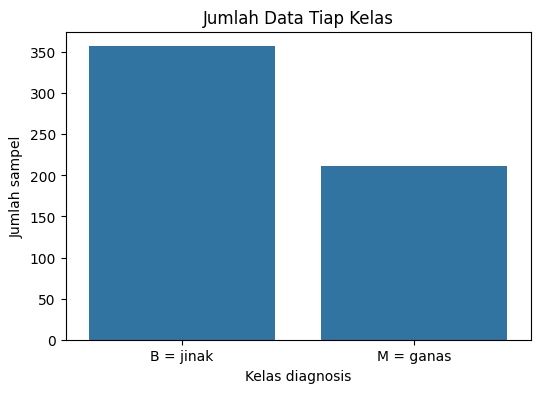

In [4]:
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x='diagnosis')
plt.xticks([0, 1], ['B = jinak', 'M = ganas'])
plt.title('Jumlah Data Tiap Kelas')
plt.xlabel('Kelas diagnosis')
plt.ylabel('Jumlah sampel')
plt.show()


### Visualisasi 2: Box plot

Box plot membandingkan `radius_mean` pada kelas jinak dan ganas. Jika posisi tengah atau penyebaran kedua kelompok terlihat berbeda, fitur ini mungkin membantu model membedakan kedua kelas.

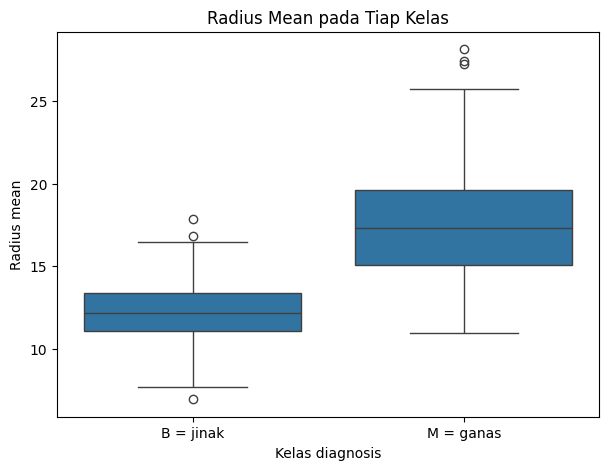

In [5]:
plt.figure(figsize=(7, 5))
sns.boxplot(data=df, x='diagnosis', y='radius_mean')
plt.xticks([0, 1], ['B = jinak', 'M = ganas'])
plt.title('Radius Mean pada Tiap Kelas')
plt.xlabel('Kelas diagnosis')
plt.ylabel('Radius mean')
plt.show()


### Visualisasi 3: Heatmap korelasi

Heatmap menunjukkan hubungan antar fitur angka. Warna yang lebih kuat berarti hubungannya lebih besar. Jika dua fitur sangat mirip, keduanya bisa memberi informasi yang hampir sama.

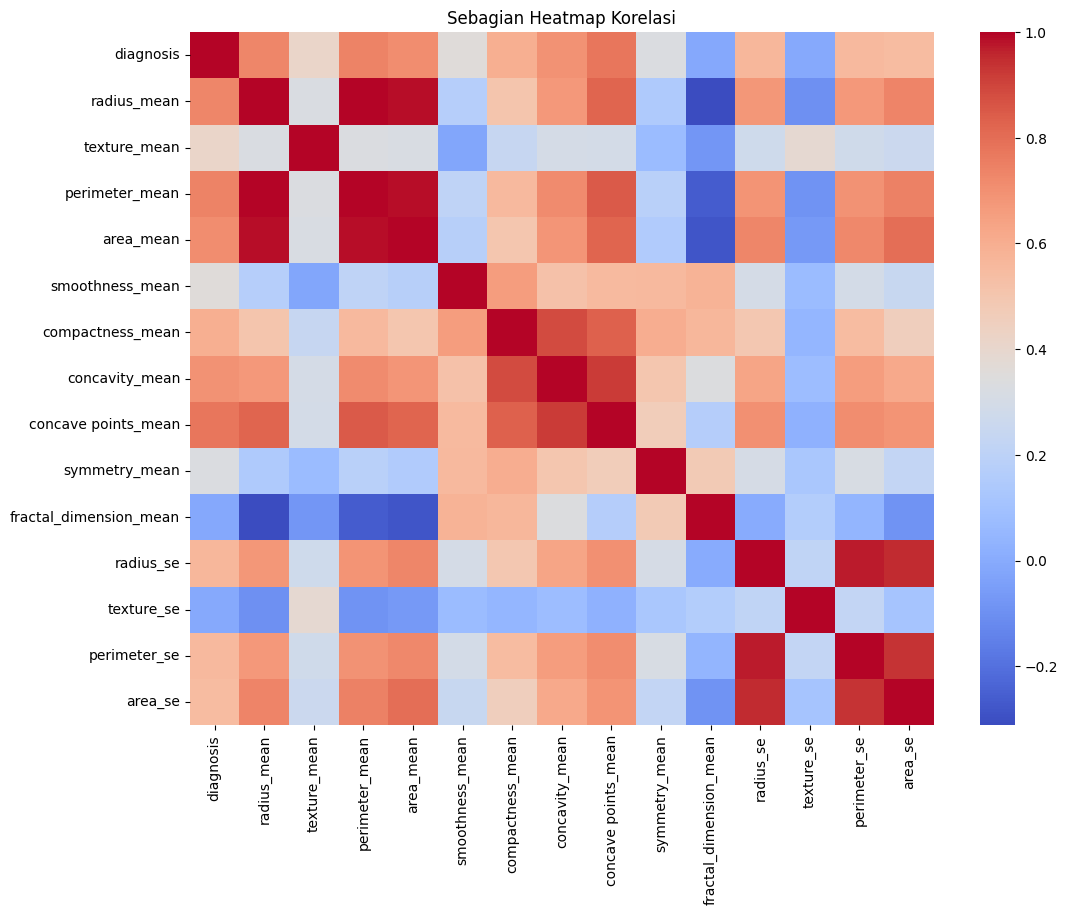

In [6]:
plt.figure(figsize=(12, 9))
correlation = df.corr(numeric_only=True)
sns.heatmap(correlation.iloc[:15, :15], cmap='coolwarm')
plt.title('Sebagian Heatmap Korelasi')
plt.show()


### Kesimpulan sementara dari grafik

Dari grafik, kita bisa membandingkan jumlah kelas dan melihat apakah `radius_mean` memiliki pola yang berbeda antara kelas 0 dan 1. Heatmap juga menunjukkan bahwa beberapa fitur memiliki hubungan yang cukup kuat. Hal ini wajar karena beberapa fitur mengukur bagian yang hampir sama dari sel.

## B3. Preprocessing

Preprocessing adalah tahap menyiapkan data sebelum dipakai model.

- Baris duplikat dihapus supaya satu sampel tidak dihitung dua kali.
- Jika ada data kosong, nilainya diisi dengan median.
- Semua fitur sudah berupa angka setelah kolom teks target diubah menjadi 0 dan 1.
- Jumlah kelas dicek lewat grafik. Karena kelas jinak lebih banyak daripada kelas ganas, kita memakai `class_weight='balanced'`. Cara ini memberi bobot lebih besar pada kelas yang jumlahnya lebih sedikit.

Model tetap dibuat di dalam pipeline supaya langkah preprocessing dilakukan dengan aturan yang sama pada data latih dan data uji.

In [7]:
df = df.drop_duplicates().copy()
X = df.drop(columns='diagnosis')
y = df['diagnosis']

print('Jumlah fitur sebelum pemilihan:', X.shape[1])
print('Perbandingan kelas:')
print(y.value_counts(normalize=True).rename(index={0: 'B = jinak', 1: 'M = ganas'}))


Jumlah fitur sebelum pemilihan: 30
Perbandingan kelas:
diagnosis
B = jinak    0.627417
M = ganas    0.372583
Name: proportion, dtype: float64


## B4. Pemilihan Fitur

Kita memakai `SelectKBest` untuk memilih 10 fitur yang paling berhubungan dengan target. Metode ini menggunakan uji statistik sederhana bernama ANOVA.

Fitur yang terpilih dipakai oleh model. Fitur lainnya tidak dipakai pada perhitungan akhir. Nama fitur yang dipakai dan yang tidak dipakai akan ditampilkan setelah model dilatih.

## B5. Pembagian Data

Data dibagi menjadi 80% data latih dan 20% data uji. Data latih dipakai untuk membuat model, sedangkan data uji dipakai untuk melihat kemampuan model pada data baru.

`stratify=y` digunakan supaya perbandingan kelas jinak dan ganas di data latih dan data uji tetap mirip. `random_state=42` membuat hasil pembagian data tetap sama saat notebook dijalankan ulang.

In [8]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

model = Pipeline([
    ('isi_data_kosong', SimpleImputer(strategy='median')),
    ('scaling', StandardScaler()),
    ('pilih_10_fitur', SelectKBest(f_classif, k=10)),
    ('logistic_regression', LogisticRegression(
        max_iter=2000,
        class_weight='balanced'
    ))
])

model.fit(X_train, y_train)
print('Jumlah data latih:', len(X_train))
print('Jumlah data uji:', len(X_test))


Jumlah data latih: 455
Jumlah data uji: 114


## B6. Pemodelan dan interpretasi koefisien

Model yang digunakan adalah `LogisticRegression`. Model ini menghitung peluang data masuk ke kelas 0 atau kelas 1.

- Koefisien positif berarti kenaikan fitur cenderung membuat peluang masuk ke kelas 1 meningkat.
- Koefisien negatif berarti kenaikan fitur cenderung membuat peluang masuk ke kelas 1 menurun.
- Nilai koefisien yang lebih jauh dari nol menunjukkan pengaruh yang lebih besar setelah fitur distandardisasi.

Koefisien bukan berarti kenaikan satu angka pada fitur pasti menaikkan diagnosis. Koefisien hanya menunjukkan arah hubungan dalam model.

In [9]:
selected_mask = model.named_steps['pilih_10_fitur'].get_support()
selected_features = X.columns[selected_mask]
discarded_features = X.columns[~selected_mask]
coefficients = model.named_steps['logistic_regression'].coef_[0]

coef_table = pd.DataFrame({
    'fitur': selected_features,
    'koefisien': coefficients,
    'nilai_absolut': np.abs(coefficients)
}).sort_values('nilai_absolut', ascending=False)

print('Fitur yang dipertahankan:')
display(coef_table)
print('Fitur yang tidak dipakai:', list(discarded_features))
print('Intercept:', model.named_steps['logistic_regression'].intercept_[0])


Fitur yang dipertahankan:


,fitur,koefisien,nilai_absolut
7,area_worst,1.862988,1.862988
5,radius_worst,1.765171,1.765171
4,concave points_mean,1.190969,1.190969
6,perimeter_worst,1.133170,1.133170
9,concave points_worst,1.073927,1.073927
1,perimeter_mean,-0.503404,0.503404
8,concavity_worst,0.446721,0.446721
0,radius_mean,-0.380306,0.380306
3,concavity_mean,-0.116498,0.116498
2,area_mean,0.079310,0.079310


Fitur yang tidak dipakai: ['texture_mean', 'smoothness_mean', 'compactness_mean', 'symmetry_mean', 'fractal_dimension_mean', 'radius_se', 'texture_se', 'perimeter_se', 'area_se', 'smoothness_se', 'compactness_se', 'concavity_se', 'concave points_se', 'symmetry_se', 'fractal_dimension_se', 'texture_worst', 'smoothness_worst', 'compactness_worst', 'symmetry_worst', 'fractal_dimension_worst']
Intercept: 0.018746536025764954


## B7. Evaluasi

Kita memakai beberapa metrik.

- **Accuracy**: persentase semua tebakan yang benar.
- **Precision**: dari semua data yang diprediksi sebagai kelas 1, berapa yang benar-benar kelas 1.
- **Recall**: dari semua data yang benar-benar kelas 1, berapa yang berhasil ditemukan model.
- **F1-score**: gabungan antara precision dan recall.
- **AUC**: kemampuan model membedakan kelas 0 dan kelas 1. Nilai yang lebih dekat ke 1 biasanya lebih baik.

Untuk data pemeriksaan kesehatan, recall kelas 1 cukup penting. Kita tidak ingin terlalu banyak sampel yang sebenarnya ganas tetapi diprediksi sebagai jinak.

In [10]:
prediksi = model.predict(X_test)
probabilitas = model.predict_proba(X_test)[:, 1]

print(classification_report(
    y_test, prediksi,
    target_names=['B = jinak', 'M = ganas']
))
print('Accuracy :', round(accuracy_score(y_test, prediksi), 4))
print('Precision:', round(precision_score(y_test, prediksi), 4))
print('Recall   :', round(recall_score(y_test, prediksi), 4))
print('F1-score :', round(f1_score(y_test, prediksi), 4))
print('AUC      :', round(roc_auc_score(y_test, probabilitas), 4))


              precision    recall  f1-score   support

   B = jinak       0.97      0.96      0.97        72
   M = ganas       0.93      0.95      0.94        42

    accuracy                           0.96       114
   macro avg       0.95      0.96      0.95       114
weighted avg       0.96      0.96      0.96       114

Accuracy : 0.9561
Precision: 0.9302
Recall   : 0.9524
F1-score : 0.9412
AUC      : 0.9974


### Confusion matrix

Confusion matrix menunjukkan jumlah prediksi yang benar dan salah.

- **True Negative**: sampel jniak diprediksi jinak.
- **True Positive**: sampel ganas diprediksi ganas.
- **False Positive**: sampel jinak diprediksi ganas.
- **False Negative**: sampel ganas diprediksi jinak.

Dalam kasus ini, false negative perlu diperhatikan karena berarti sampel ganas tidak terdeteksi oleh model.

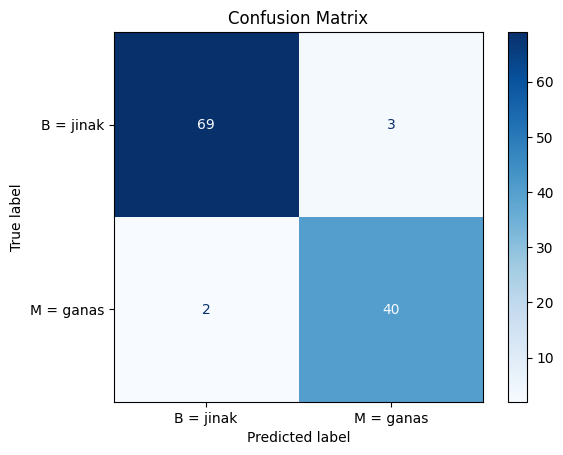

In [11]:
ConfusionMatrixDisplay.from_predictions(
    y_test, prediksi,
    display_labels=['B = jinak', 'M = ganas'],
    cmap='Blues'
)
plt.title('Confusion Matrix')
plt.show()


### ROC curve

ROC curve memperlihatkan kemampuan model saat batas prediksinya diubah. Nilai AUC ditampilkan di legenda. Semakin dekat nilai AUC ke 1, semakin baik model membedakan kedua kelas.

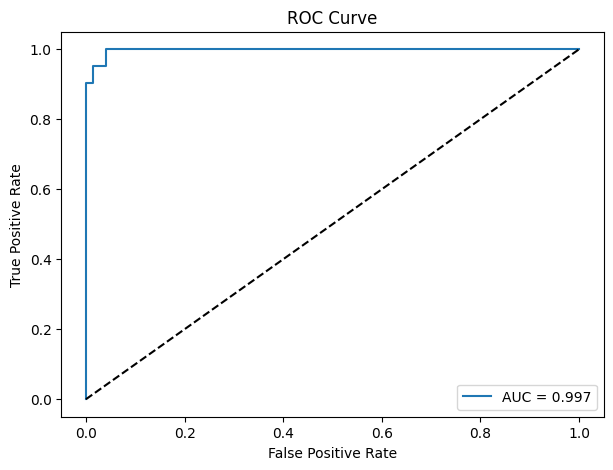

In [12]:
fpr, tpr, _ = roc_curve(y_test, probabilitas)
auc = roc_auc_score(y_test, probabilitas)
plt.figure(figsize=(7, 5))
plt.plot(fpr, tpr, label=f'AUC = {auc:.3f}')
plt.plot([0, 1], [0, 1], 'k--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve')
plt.legend()
plt.show()


## B8. Analisis Performa

Hasil accuracy, precision, recall, F1-score, dan AUC digunakan bersama-sama. Accuracy yang tinggi belum tentu cukup jika jumlah kelas tidak seimbang. Karena itu, recall dan F1-score juga perlu dilihat.

Perhatikan confusion matrix. Jika false negative lebih banyak, berarti masih ada sampel ganas yang diprediksi sebagai jinak. Untuk kasus kesehatan, kesalahan ini perlu diperhatikan karena akibatnya bisa lebih serius.

Fitur yang paling berpengaruh dapat dilihat dari nilai absolut koefisien terbesar. Koefisien positif berarti fitur tersebut cenderung menaikkan peluang kelas 1, sedangkan koefisien negatif cenderung menurunkannya.

Model ini masih punya keterbatasan. Hasilnya bergantung pada fitur yang tersedia dan kualitas data. Logistic Regression juga membuat batas pemisah yang cukup sederhana, sehingga mungkin belum bisa menangkap semua pola pada data sel. Selain itu, hasil model tidak boleh dipakai sebagai pengganti keputusan dokter.